

## 1. Load Results and Align Spots and Proteins

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator
from scipy.optimize import linear_sum_assignment
from sklearn import metrics

SAMPLE = "HLN_A1"

RESULTS = Path("../results/missing-modality")
folders = {"SpaGenFuse": RESULTS / SAMPLE / "spagenfuse", "SpaMosaic": RESULTS / SAMPLE / "spamosaic"}
rna = {"SpaGenFuse": sc.read_h5ad(folders["SpaGenFuse"] / "rna_spatial_domain_results.h5ad"),
       "SpaMosaic": sc.read_h5ad(folders["SpaMosaic"] / "rna_results.h5ad")}
adt = {"SpaGenFuse": sc.read_h5ad(folders["SpaGenFuse"] / "adt_imputation_results.h5ad"),
       "SpaMosaic": sc.read_h5ad(folders["SpaMosaic"] / "adt_results.h5ad")}
spots = rna["SpaGenFuse"].obs_names
proteins = adt["SpaGenFuse"].var_names.intersection(adt["SpaMosaic"].var_names, sort=False)
rna["SpaMosaic"] = rna["SpaMosaic"][spots]
adt = {method: a[spots, proteins] for method, a in adt.items()}
xy = np.asarray(rna["SpaGenFuse"].obsm["spatial"])
labels = rna["SpaGenFuse"].obs["manual-anno"].to_numpy()
missing = ~rna["SpaGenFuse"].obs["adt_observed_mask"].to_numpy(dtype=bool)
assert np.array_equal(missing, rna["SpaMosaic"].obs["is_imputed"].to_numpy(dtype=bool))
domain_keys = {"SpaGenFuse": "domain", "SpaMosaic": "mclust"}
label_keys = {"SpaGenFuse": "manual-anno", "SpaMosaic": "manual_anno"}

def dense(x):
    return x.toarray() if hasattr(x, "toarray") else np.asarray(x)

truth = dense(adt["SpaGenFuse"].layers["counts"])
plt.rcParams.update({"figure.dpi": 120, "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 10})

## 2. A: RNA and Protein Inputs with the Missing Region

Total counts per spot are scaled to 0-1 using the 1st and 99th percentiles. Gray indicates the missing region.

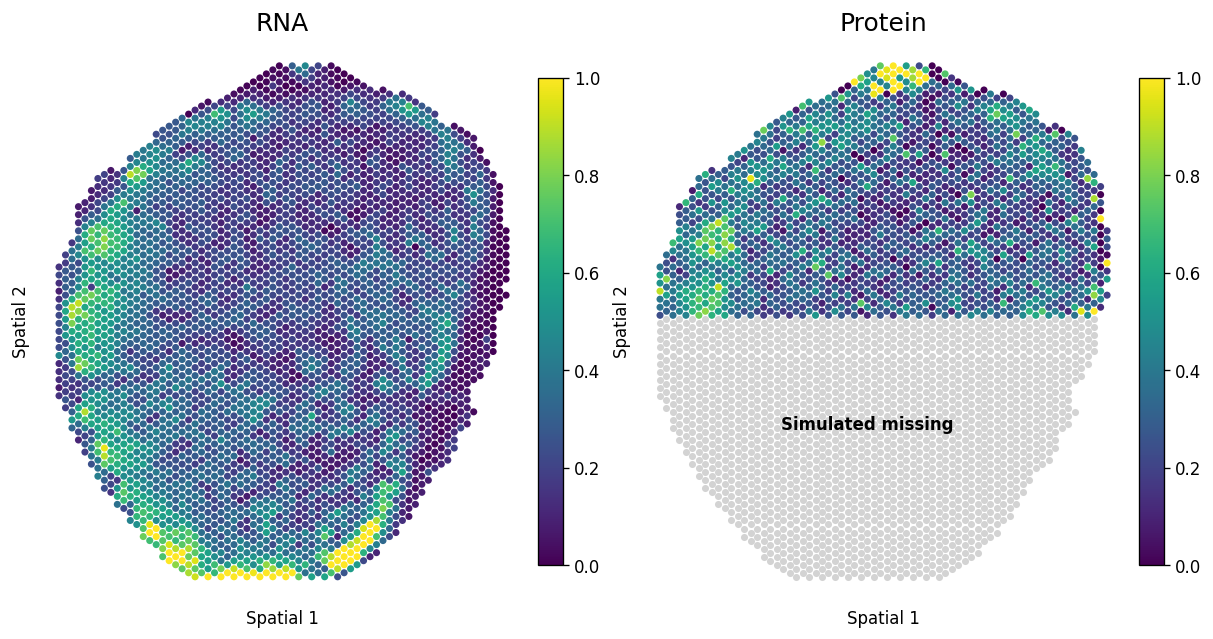

In [34]:
def spatial_axis(ax, title):
    ax.set_title(title, fontsize=15)
    ax.set_xlabel('Spatial 1')
    ax.set_ylabel('Spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_box_aspect(4 / 3.5)
    for spine in ax.spines.values():
        spine.set_visible(False)

def plot_domains(ax, xy, values, title, legend=True):
    values = np.asarray(values).astype(str)
    categories = sorted(pd.unique(values).tolist(), key=str.casefold)
    cmap = plt.get_cmap('tab20', max(len(categories), 1))
    for category_id, category in enumerate(categories):
        category_mask = values == category
        ax.scatter(xy[category_mask, 0], xy[category_mask, 1], c=[cmap(category_id)], s=20, linewidths=0, label=category)
    spatial_axis(ax, title)
    if legend:
        ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=2 if len(categories) > 8 else 1, frameon=False, fontsize=10, markerscale=1.3, handletextpad=0.4, columnspacing=0.9)

def scale(values):
    lo, hi = np.quantile(values[np.isfinite(values)], [0.01, 0.99])
    if hi <= lo:
        lo, hi = (np.nanmin(values), np.nanmax(values))
    return np.clip((values - lo) / (hi - lo), 0, 1) if hi > lo else np.zeros_like(values, dtype=float)
totals = [np.asarray(rna['SpaGenFuse'].layers['counts'].sum(axis=1)).ravel(), truth.sum(axis=1)]
fig_input, axes_input = plt.subplots(1, 2, figsize=(10, 5.5), layout='constrained')
for ax, total, title in zip(axes_input, totals, ['RNA', 'Protein']):
    values = scale(total)
    visible = np.isfinite(values) if title == 'RNA' else ~missing & np.isfinite(values)
    if title == 'Protein':
        ax.scatter(*xy[missing].T, c='#d3d3d3', s=18, linewidths=0)
    points = ax.scatter(*xy[visible].T, c=values[visible], s=18, cmap='viridis', vmin=0, vmax=1, linewidths=0)
    if title == 'Protein' and missing.any():
        ax.text(*np.median(xy[missing], axis=0), 'Simulated missing', ha='center', va='center', fontsize=10, fontweight='bold', color='#000000')
    spatial_axis(ax, title)
    fig_input.colorbar(points, ax=ax, shrink=0.75, pad=0.02)
plt.show()

## 3. B/C: Manual Annotations and Spatial Domains

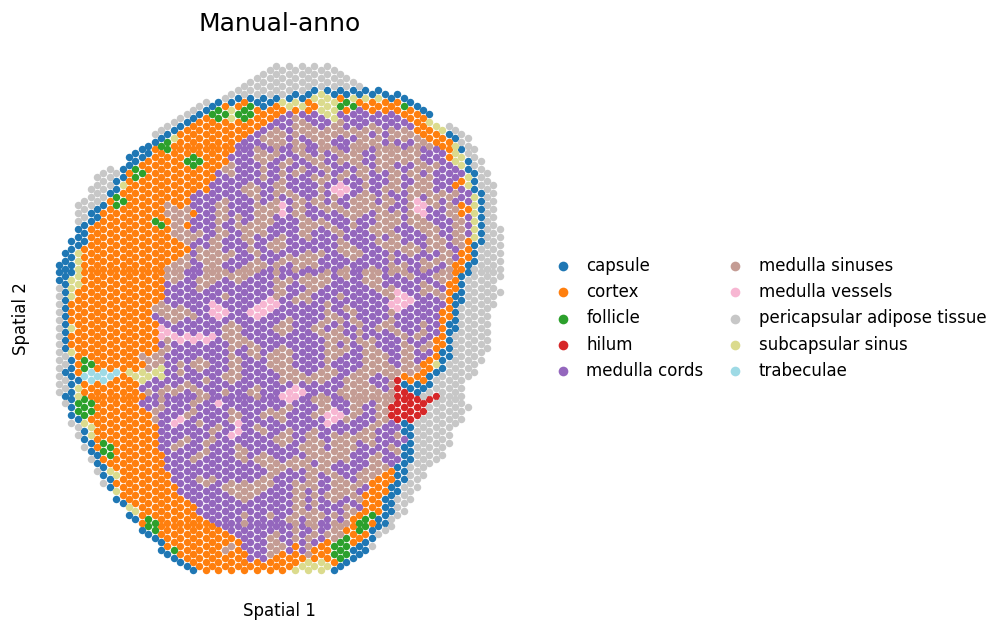

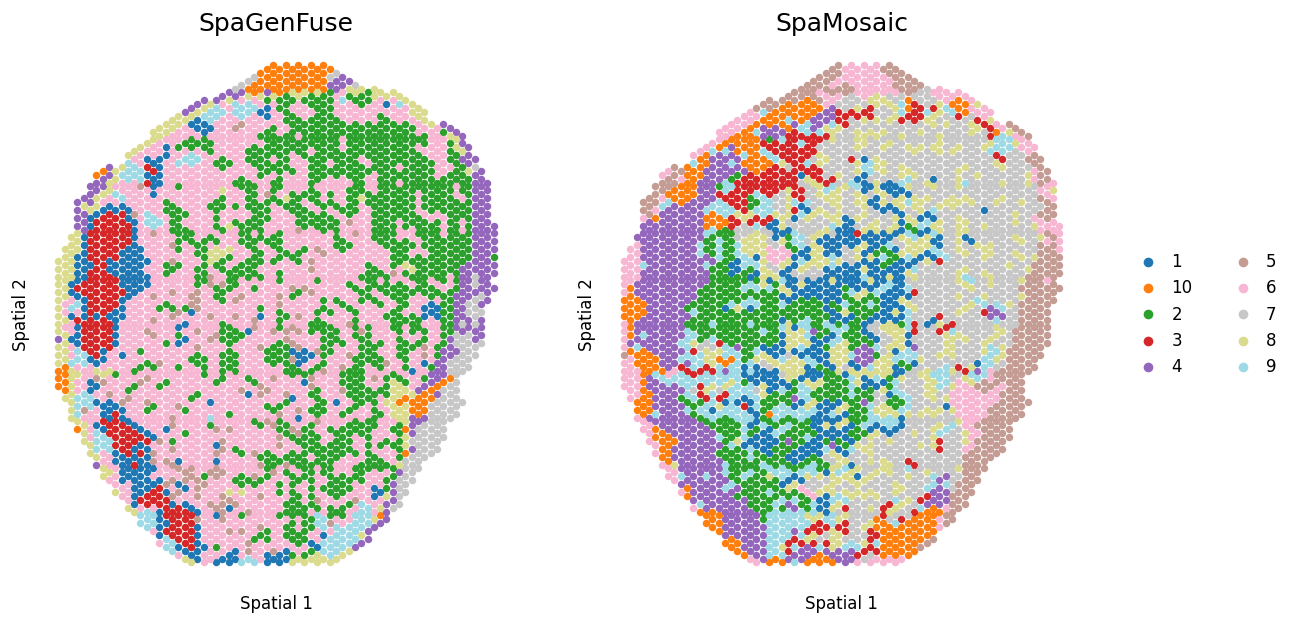

In [35]:
domain_predictions = {method: a.obs[domain_keys[method]].to_numpy() for method, a in rna.items()}
fig_gt, ax_gt = plt.subplots(figsize=(10, 6), constrained_layout=False)
plot_domains(ax_gt, xy, labels, 'Manual-anno')
fig_gt.subplots_adjust(right=0.68)
plt.show()
fig_domains, axes_domains = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=False, gridspec_kw={'wspace': 0.16})
plot_domains(axes_domains[0], xy, domain_predictions['SpaGenFuse'], 'SpaGenFuse', legend=False)
plot_domains(axes_domains[1], xy, domain_predictions['SpaMosaic'], 'SpaMosaic', legend=False)
shared_handles, shared_labels = axes_domains[1].get_legend_handles_labels()
fig_domains.legend(shared_handles, shared_labels, loc='center left', bbox_to_anchor=(0.82, 0.5), ncol=2 if len(shared_labels) > 8 else 1, frameon=False, fontsize=10, markerscale=1.3, handletextpad=0.4)
fig_domains.subplots_adjust(right=0.8, bottom=0.12)
plt.show()

## 4. D: Spatial-Domain Clustering Metrics

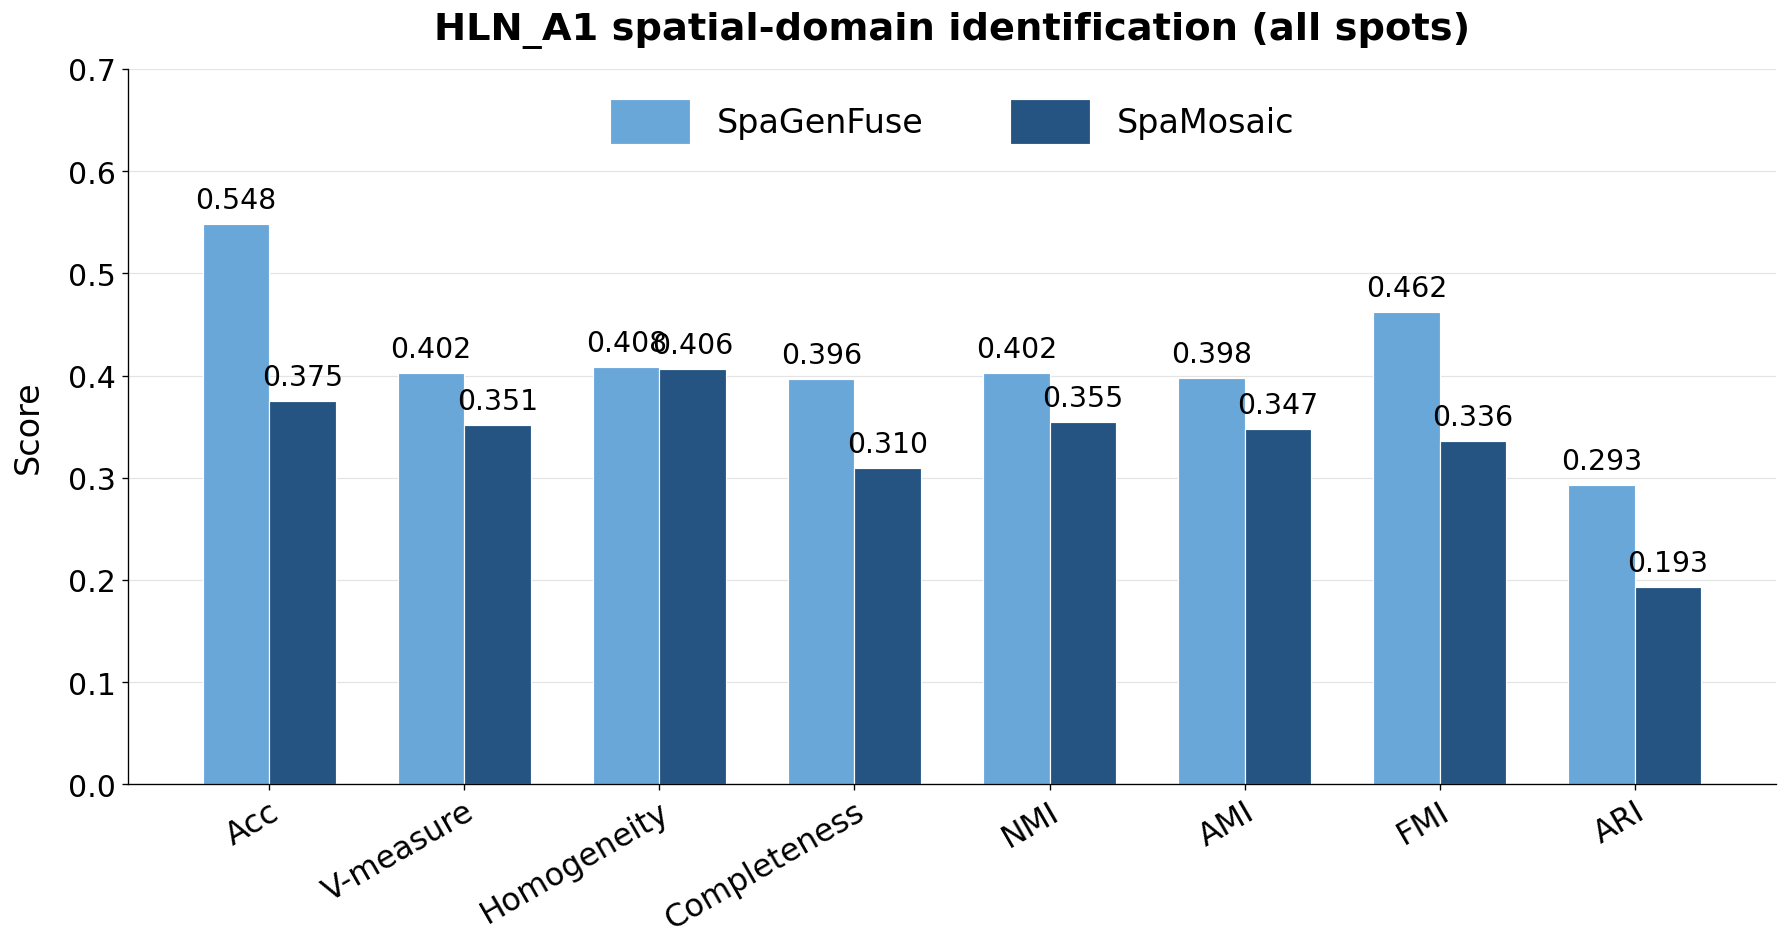

In [36]:
def scores(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    valid = pd.notna(truth) & pd.notna(prediction)
    truth, prediction = truth[valid].astype(str), prediction[valid].astype(str)
    contingency = metrics.cluster.contingency_matrix(truth, prediction)
    rows, cols = linear_sum_assignment(-contingency)
    return {
        "Acc": contingency[rows, cols].sum() / len(truth),
        "V-measure": metrics.v_measure_score(truth, prediction),
        "Homogeneity": metrics.homogeneity_score(truth, prediction),
        "Completeness": metrics.completeness_score(truth, prediction),
        "NMI": metrics.normalized_mutual_info_score(truth, prediction, average_method="geometric"),
        "AMI": metrics.adjusted_mutual_info_score(truth, prediction),
        "FMI": metrics.fowlkes_mallows_score(truth, prediction),
        "ARI": metrics.adjusted_rand_score(truth, prediction),
    }

domain_scores = pd.DataFrame({method: scores(labels, a.obs[domain_keys[method]]) for method, a in rna.items()}).T

DOMAIN_METRICS = list(domain_scores.columns)
METHOD_ORDER = list(folders)
METHOD_COLORS = {"SpaGenFuse": "#69A7D9", "SpaMosaic": "#255482"}
x = np.arange(len(DOMAIN_METRICS))
bar_width = 0.34
fig_domain_metrics, ax_domain_metrics = plt.subplots(figsize=(15, 8))
for method_id, method_name in enumerate(METHOD_ORDER):
    offset = (method_id - (len(METHOD_ORDER) - 1) / 2) * bar_width
    bars = ax_domain_metrics.bar(x + offset, domain_scores.loc[method_name].to_numpy(dtype=float), width=bar_width, color=METHOD_COLORS[method_name], edgecolor='white', linewidth=0.7, label=method_name)
    ax_domain_metrics.bar_label(bars, fmt='%.3f', padding=6, fontsize=17)
score_max = float(domain_scores.to_numpy().max())
y_upper = min(1.0, max(0.5, np.ceil((score_max + 0.08) * 10) / 10))
ax_domain_metrics.set_ylim(0, y_upper)
ax_domain_metrics.set_xticks(x)
ax_domain_metrics.set_xticklabels(DOMAIN_METRICS, fontsize=19, rotation=30, ha='right', rotation_mode='anchor')
ax_domain_metrics.tick_params(axis='y', labelsize=18)
ax_domain_metrics.set_ylabel('Score', fontsize=20, labelpad=14)
ax_domain_metrics.set_title(f'{SAMPLE} spatial-domain identification (all spots)', fontsize=23, fontweight='bold', pad=18)
ax_domain_metrics.grid(axis='y', color='#D9D9D9', linewidth=0.7, alpha=0.7)
ax_domain_metrics.set_axisbelow(True)
ax_domain_metrics.spines['top'].set_visible(False)
ax_domain_metrics.spines['right'].set_visible(False)
ax_domain_metrics.legend(frameon=False, loc='upper center', ncol=2, fontsize=20, handlelength=2.4, handleheight=1.7, columnspacing=2.6)
fig_domain_metrics.tight_layout()
plt.show()

## 5. E: Clustering Metrics across Missing Rates

Markers show the actual results at the three missing rates. PCHIP curves are used only for visual interpolation.

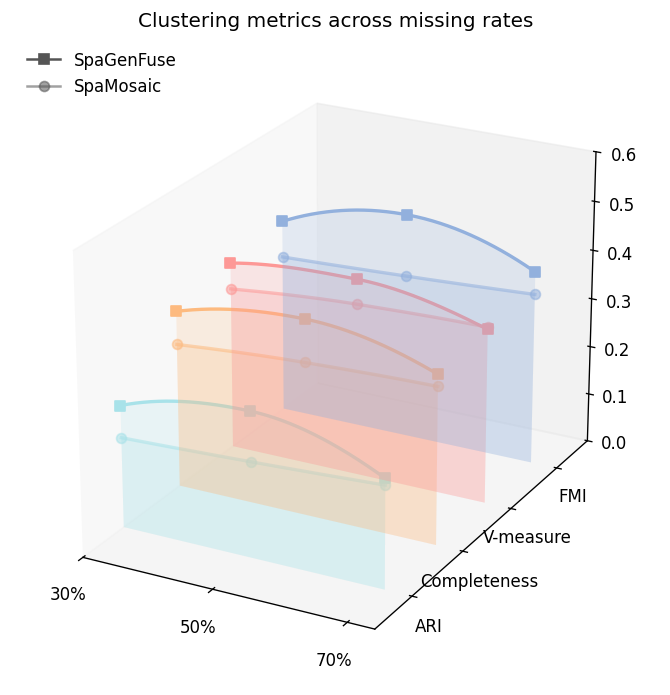

In [37]:
rates = [0.3, 0.5, 0.7]
trend_scores = {}
for method, folder in folders.items():
    for rate in rates:
        a = sc.read_h5ad(folder / f"domain_missing_{rate:.1f}.h5ad", backed="r")
        try:
            trend_scores[method, rate] = scores(a.obs[label_keys[method]], a.obs[domain_keys[method]])
        finally:
            a.file.close()

names = ['ARI', 'Completeness', 'V-measure', 'FMI']
colors = ['#A8E2E9', '#FDBA7F', '#FD9896', '#92B0DD']
markers = {'SpaGenFuse': 's', 'SpaMosaic': 'o'}
positions = np.arange(len(names)) * 2.0
fig_trend = plt.figure(figsize=(10, 7))
ax_trend = fig_trend.add_subplot(111, projection='3d')
for position, name, color in zip(positions, names, colors):
    for method in folders:
        z = np.array([trend_scores[method, rate][name] for rate in rates])
        x = np.linspace(rates[0], rates[-1], 201)
        curve = PchipInterpolator(rates, z)(x)
        vertices = [(x[0], 0), *zip(x, curve), (x[-1], 0)]
        curtain = PolyCollection([vertices], facecolors=[color], edgecolors='none', alpha=0.2)
        ax_trend.add_collection3d(curtain, zs=position, zdir='y')
        alpha = 1.0 if method == 'SpaGenFuse' else 0.55
        ax_trend.plot(x, np.full_like(x, position), curve, color=color, alpha=alpha, linewidth=2)
        ax_trend.scatter(rates, np.full_like(rates, position), z, color=color, alpha=alpha, marker=markers[method], s=35, depthshade=False)
z_values = [value[name] for value in trend_scores.values() for name in names]
ax_trend.set(xlim=(0.3, 0.74), ylim=(-1.4, positions[-1] + 1.4), zlim=(min(0, min(z_values) - 0.03), max(0.6, max(z_values) + 0.05)), title='Clustering metrics across missing rates')
ax_trend.set_xticks(rates, ['30%', '50%', '70%'])
ax_trend.set_yticks(positions, names)
ax_trend.view_init(elev=23, azim=-62)
ax_trend.set_box_aspect((1, 1.5, 1))
ax_trend.grid(False)
ax_trend.legend(handles=[Line2D([0], [0], color='#555555', marker=markers[method], alpha=1.0 if method == 'SpaGenFuse' else 0.55, label=method) for method in folders], frameon=False, loc='upper left')
plt.show()

## 6. F/G: Per-Protein Correlations in the Missing Region

Boxes span the interquartile range (IQR), center lines indicate medians, and whiskers extend to the most extreme values within 1.5 times the IQR. Overlaid points include outliers.

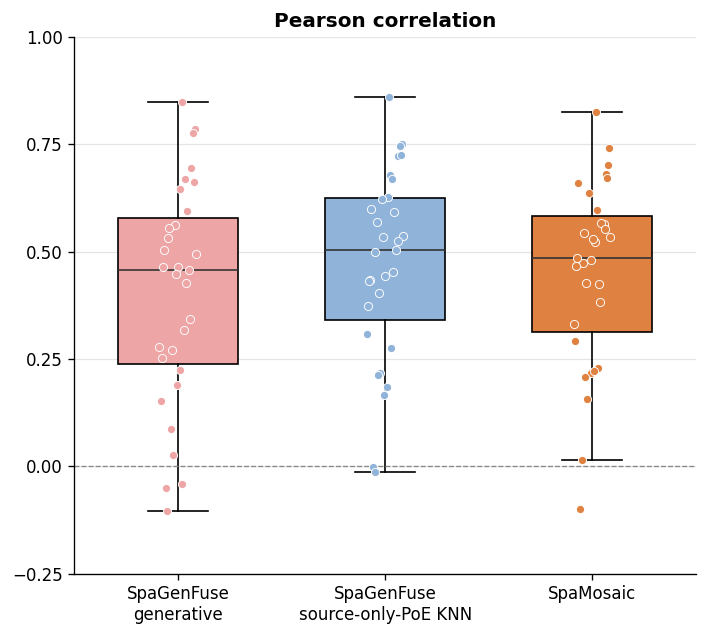

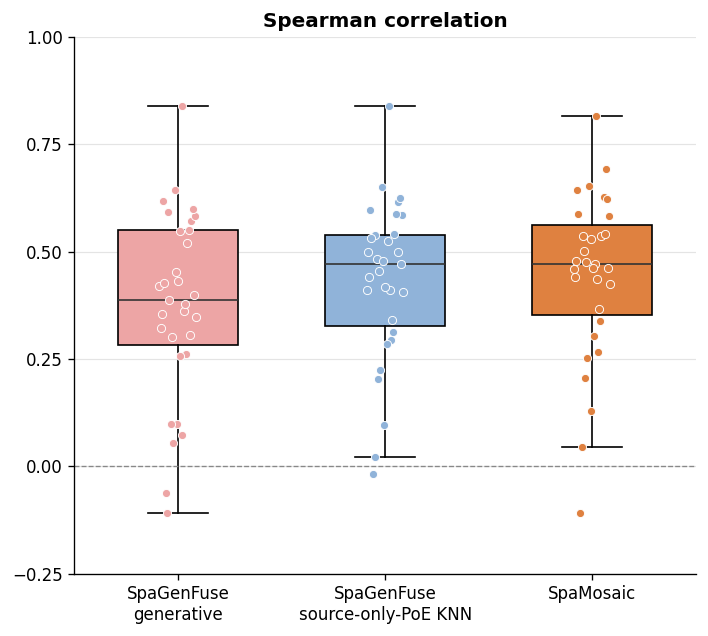

In [38]:
predictions = {
    "SpaGenFuse\ngenerative": dense(adt["SpaGenFuse"].layers["imputation_completed_generative"]),
    "SpaGenFuse\nsource-only-PoE KNN": dense(adt["SpaGenFuse"].layers["imputation_completed_source_only_poe_knn"]),
    "SpaMosaic": dense(adt["SpaMosaic"].layers["imputed_counts"]),
}
reference = pd.DataFrame(truth[missing]).replace([np.inf, -np.inf], np.nan)
for metric in ["pearson", "spearman"]:
    values = pd.DataFrame({
        method: pd.DataFrame(prediction[missing]).replace([np.inf, -np.inf], np.nan).corrwith(reference, method=metric)
        for method, prediction in predictions.items()
    }).dropna()  # For each metric, retain only proteins with valid correlations for all three methods.
    fig, ax = plt.subplots(figsize=(6, 5.4))
    boxes = ax.boxplot(values.to_numpy(), patch_artist=True, widths=0.58, showfliers=False,
                       medianprops={"color": "#333333"})
    jitter = ((np.arange(len(values)) * 0.61803398875) % 1 - 0.5) * 0.18
    for i, (patch, color) in enumerate(zip(boxes["boxes"], ["#EDA5A5", "#90B3D9", "#DF8140"])):
        patch.set_facecolor(color)
        ax.scatter(i + 1 + jitter, values.iloc[:, i], s=24, c=color, edgecolors="white", linewidths=0.55, zorder=3)
    ax.set_xticks([1, 2, 3], values.columns)
    ax.set_ylim(-0.25, 1.0)
    ax.set_yticks(np.arange(-0.25, 1.01, 0.25))
    ax.set_title(f"{metric.title()} correlation", fontweight="bold")
    ax.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
